# Lights Out · Phase 1 data profile

What we have, how complete it is, what needs fixing, and a first look at the patterns.
Run top to bottom from this folder (`03_analysis`). Needs `pandas` and `matplotlib`.

In [1]:
import pandas as pd, numpy as np, glob, matplotlib.pyplot as plt, matplotlib.dates as mdates
from pathlib import Path
RAW = Path('../01_data/raw')
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)

# Oat, Forest, Tomato palette
OAT, CARD, GREEN, GREEN2, OCHRE, TOMATO, SLATE, INK, GRID = '#EEE5D4','#F7F1E6','#1D4A35','#3B8A60','#B87318','#F2462E','#7D8D99','#16382A','#E6DCC8'
plt.rcParams.update({'figure.facecolor': CARD, 'axes.facecolor': CARD, 'axes.edgecolor': GRID, 'axes.labelcolor': INK,
    'xtick.color': '#4F5E52', 'ytick.color': '#4F5E52', 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': .8,
    'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10.5, 'axes.titlesize': 13,
    'axes.titleweight': 'bold', 'axes.titlecolor': GREEN, 'axes.titlelocation': 'left', 'figure.dpi': 110})

## 1. The three sources

In [2]:
# Hourly, downloaded (PGCB via Mendeley): Apr 2015 to 8 Mar 2026
hm = pd.read_csv(RAW/'hourly_pgcb_2015_2026/pgcb_V1_raw.csv', parse_dates=['datetime'])
# Hourly, our collector (PGCB portal): 1 Mar 2026 onward
hp = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(str(RAW/'pgcb_portal_2026/pgcb_hourly_*.csv')))])
hp = hp[hp.cell_count > 0].copy()
hp['datetime'] = pd.to_datetime(hp.date + ' ' + hp.time, format='%d-%m-%Y %H:%M:%S')
hp = hp.rename(columns={'loadshed_mw_raw': 'load_shedding', 'demand_mw_raw': 'demand_mw'})
# Daily (BPDB via Mendeley): 21 Nov 2019 to 3 Aug 2026
dd = pd.read_csv(RAW/'daily_bpdb_2019_2026/Bangladesh_Electricity_Dataset_2019_2026.csv', parse_dates=['Date'])

pd.DataFrame([
    ['Hourly, downloaded', 'PGCB via Mendeley', hm.datetime.min(), hm.datetime.max(), len(hm), hm.shape[1]],
    ['Hourly, collected', 'PGCB portal (our script)', hp.datetime.min(), hp.datetime.max(), len(hp), 17],
    ['Daily', 'BPDB via Mendeley', dd.Date.min(), dd.Date.max(), len(dd), dd.shape[1]],
], columns=['Source', 'From', 'First', 'Last', 'Rows', 'Columns'])

,Source,From,First,Last,Rows,Columns
0,"Hourly, downloaded",PGCB via Mendeley,2015-04-17 18:30:00,2026-03-08 23:00:00,94934,15
1,"Hourly, collected",PGCB portal (our script),2026-03-01 00:00:00,2026-11-15 23:00:00,6507,17
2,Daily,BPDB via Mendeley,2019-11-21 00:00:00,2026-08-03 00:00:00,2428,45


### The two hourly sources agree exactly
For 1 to 8 March 2026, both hourly sources hold the same 192 hours. Every column matches, including
load shedding, so we join them: the download up to 28 February 2026, our collector from 1 March.

In [3]:
cols = ['generation_mw','demand_mw','load_shedding','gas','liquid_fuel','coal','hydro','solar','wind',
        'india_bheramara_hvdc','india_tripura','india_adani','nepal']
m = hm.merge(hp, on='datetime', suffixes=('_dl', '_col'))
print(f'overlap: {len(m)} hours')
print(pd.Series({c: ((m[c+'_dl'] - m[c+'_col']).abs() < 1).mean() for c in cols}).map('{:.0%}'.format).to_string())

hourly = pd.concat([hm[hm.datetime < '2026-03-01'][['datetime'] + cols + ['remarks']],
                    hp[['datetime'] + cols + ['remarks']]], ignore_index=True).sort_values('datetime')
hourly['source'] = np.where(hourly.datetime < '2026-03-01', 'download', 'collector')
print(f'\ncombined hourly: {len(hourly):,} rows, {hourly.datetime.min():%d %b %Y} to {hourly.datetime.max():%d %b %Y}')

overlap: 192 hours
generation_mw           100%
demand_mw               100%
load_shedding           100%
gas                     100%
liquid_fuel             100%
coal                    100%
hydro                   100%
solar                   100%
wind                    100%
india_bheramara_hvdc    100%
india_tripura           100%
india_adani             100%
nepal                   100%

combined hourly: 101,249 rows, 17 Apr 2015 to 15 Nov 2026


## 2. Completeness

In [4]:
on_hour = hourly[hourly.datetime.dt.minute == 0].drop_duplicates('datetime')
full = pd.date_range(on_hour.datetime.min().ceil('D'), on_hour.datetime.max().floor('h'), freq='h')
missing = full.difference(on_hour.datetime)
cov = (pd.Series(1, index=on_hour.datetime).resample('YE').size().to_frame('hours_present')
       .assign(hours_expected=pd.Series(1, index=full).resample('YE').size()))
cov['missing'] = cov.hours_expected - cov.hours_present
cov['complete'] = (cov.hours_present / cov.hours_expected).map('{:.1%}'.format)
cov.index = cov.index.year
print(f'missing on-the-hour readings: {len(missing):,} of {len(full):,}')
print('missing by hour of day:', pd.Series(missing.hour).value_counts().head(3).to_dict())
cov

missing on-the-hour readings: 4,975 of 101,520
missing by hour of day: {0: 3968, 23: 68, 22: 54}


,hours_present,hours_expected,missing,complete
datetime,,,,
2015,5820,6192,372,94.0%
2016,8388,8784,396,95.5%
2017,7753,8760,1007,88.5%
2018,8327,8760,433,95.1%
2019,8312,8760,448,94.9%
2020,8406,8784,378,95.7%
2021,8387,8760,373,95.7%
2022,8383,8760,377,95.7%
2023,8380,8760,380,95.7%


In [5]:
# Share of hours with a value, by column and year
nn = hourly.assign(year=hourly.datetime.dt.year).groupby('year')[cols].apply(lambda g: g.notna().mean())
nn.map(lambda v: f'{v:.0%}').T

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
generation_mw,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%
demand_mw,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,35%
load_shedding,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%
gas,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%
liquid_fuel,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%
coal,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%
hydro,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%
solar,0%,0%,29%,100%,100%,100%,100%,100%,100%,100%,100%,100%
wind,0%,0%,0%,0%,0%,0%,0%,0%,59%,100%,100%,100%
india_bheramara_hvdc,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%


In [6]:
# Daily dataset: share of days with a value for the columns we plan to use
key = ['Max. Demand at eve. peak (Generation end)', 'Evening-peak Generation (Generation end)',
       'Maximum Temperature in Dhaka was', 'Gas/LF limitation', 'Coal supply Limitation',
       'Plants under shut down/ maintenance', 'Dhaka_load', 'Rajshahi_load', 'Rangpur_load']
dd.assign(year=dd.Date.dt.year).groupby('year')[key].apply(lambda g: g.notna().mean()).map(lambda v: f'{v:.0%}').T

year,2019,2020,2021,2022,2023,2024,2025,2026
Max. Demand at eve. peak (Generation end),100%,100%,100%,100%,100%,100%,100%,100%
Evening-peak Generation (Generation end),100%,100%,100%,100%,100%,100%,100%,100%
Maximum Temperature in Dhaka was,100%,100%,100%,100%,100%,100%,97%,94%
Gas/LF limitation,100%,100%,100%,100%,100%,100%,100%,100%
Coal supply Limitation,100%,100%,100%,100%,100%,100%,100%,96%
Plants under shut down/ maintenance,100%,100%,100%,100%,100%,100%,100%,100%
Dhaka_load,100%,100%,100%,100%,100%,100%,100%,100%
Rajshahi_load,100%,100%,100%,100%,100%,100%,100%,100%
Rangpur_load,100%,100%,100%,100%,100%,100%,100%,100%


**Why about one hour a day is missing.** The downloaded dataset has no midnight (00:00) readings at all;
our collector does. So up to February 2026 every day lacks the same hour, and the hour-of-day chart below starts at
1 am for earlier years. It is a gap in how the dataset was built, not lost data.

## 3. Problems to fix in the silver layer

In [7]:
h = hourly.copy()
parts = ['gas','liquid_fuel','coal','hydro','solar','wind','india_bheramara_hvdc','india_tripura','india_adani','nepal']
h['parts_gap'] = h.generation_mw - h[parts].sum(axis=1, min_count=1)
issues = pd.Series({
    'duplicate timestamps': int(h.datetime.duplicated().sum()),
    'load shedding above 6,000 MW (impossible)': int((h.load_shedding > 6000).sum()),
    'load shedding below 0': int((h.load_shedding < 0).sum()),
    'generation below 3,000 MW or above 20,000 MW': int(((h.generation_mw < 3000) | (h.generation_mw > 20000)).sum()),
    'a single fuel above 20,000 MW (impossible)': int((h[parts] > 20000).any(axis=1).sum()),
    'fuels + imports differ from total by > 100 MW': int((h.parts_gap.abs() > 100).sum()),
    'demand recorded as exactly equal to generation': int((h.demand_mw == h.generation_mw).sum()),
    'demand missing': int(h.demand_mw.isna().sum()),
})
print(issues.to_string())
print('\nlargest load shedding values:')
print(h.nlargest(8, 'load_shedding')[['datetime','generation_mw','demand_mw','load_shedding','source']].to_string(index=False))

duplicate timestamps                                  1
load shedding above 6,000 MW (impossible)            14
load shedding below 0                                 0
generation below 3,000 MW or above 20,000 MW         36
a single fuel above 20,000 MW (impossible)           38
fuels + imports differ from total by > 100 MW      3386
demand recorded as exactly equal to generation    74050
demand missing                                     5168

largest load shedding values:
           datetime  generation_mw  demand_mw  load_shedding   source
2017-08-26 16:00:00           8068    80689.0          65359 download
2017-05-17 13:00:00           7423    74223.0          60120 download
2018-12-18 09:00:00           5563    55639.0          45068 download
2024-07-25 11:00:00          13043      436.0          13500 download
2022-10-07 02:00:00           9833    11672.0          11672 download
2022-10-15 17:00:00          10020    11211.0           9098 download
2022-06-25 14:00:00           1

**What this means**

- Demand after 23 April 2026 is empty, and in earlier years it often just repeats generation. In silver,
  **true demand = generation + load shedding** for every hour, so all years are measured the same way.
- Load shedding above 6,000 MW is a typing error in the source (the real 2026 peak is 3,757 MW). Flagged and
  set to missing, never silently dropped.
- Rows where the fuels do not add up to the total are flagged; the total is kept. Most of these are early years
  before solar, Adani and Nepal were recorded, so the gap is expected there.
- A single fuel above 20,000 MW is a typing error (one row shows about 45,000 MW of oil in 2022): set to missing.

## 4. First look

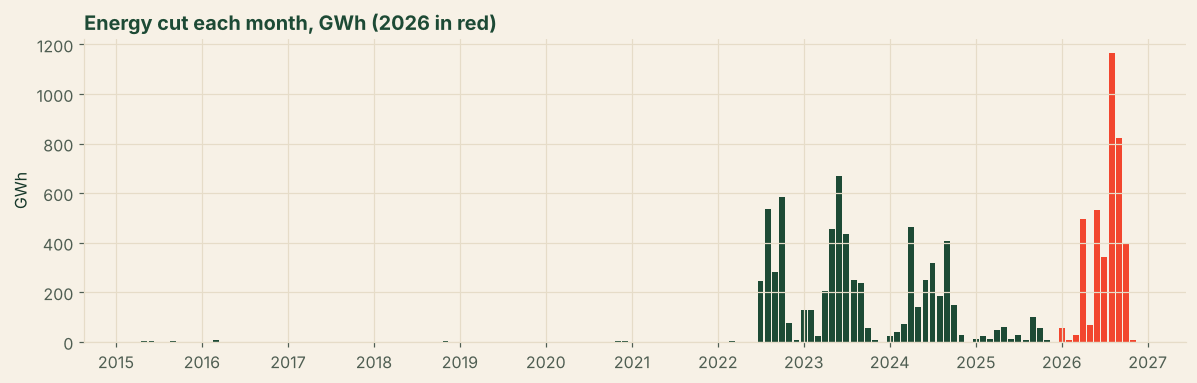

,gwh,hours_cut,peak_mw
datetime,,,
2015,7,21,1810
2016,7,35,387
2017,0,4,90
2018,3,11,1800
2019,3,12,900
2020,9,5,4626
2021,1,3,270
2022,1735,2177,5443
2023,2597,4782,3419


In [8]:
x = h[(h.load_shedding.between(0, 6000)) & (h.datetime.dt.minute == 0)].copy()
mon = x.set_index('datetime').load_shedding.resample('MS').sum() / 1000   # GWh
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(mon.index, mon.values, width=25, color=[TOMATO if d.year == 2026 else GREEN for d in mon.index])
ax.set_title('Energy cut each month, GWh (2026 in red)')
ax.set_ylabel('GWh'); ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.tight_layout(); plt.show()
yr = x.groupby(x.datetime.dt.year).load_shedding.agg(gwh=lambda s: s.sum()/1000, hours_cut=lambda s: (s > 0).sum(), peak_mw='max')
yr.round(0).astype(int)

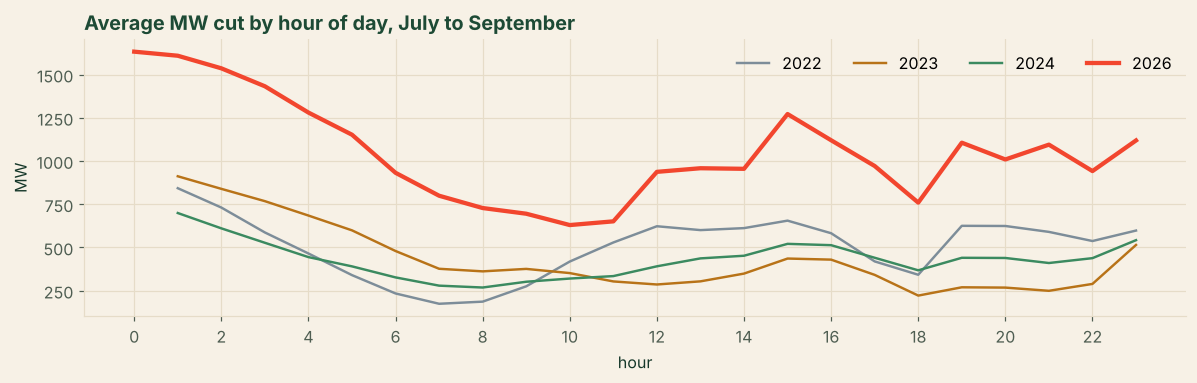

In [9]:
# When in the day: average MW cut by hour, July to September of each crisis year
s = x[x.datetime.dt.month.isin([7, 8, 9])]
prof = s.groupby([s.datetime.dt.year, s.datetime.dt.hour]).load_shedding.mean().unstack(0)
fig, ax = plt.subplots(figsize=(11, 3.6))
for y, c, w in [(2022, SLATE, 1.6), (2023, OCHRE, 1.6), (2024, GREEN2, 1.6), (2026, TOMATO, 2.8)]:
    if y in prof: ax.plot(prof.index, prof[y], color=c, lw=w, label=str(y))
ax.set_title('Average MW cut by hour of day, July to September')
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel('hour'); ax.set_ylabel('MW'); ax.legend(frameon=False, ncol=4)
plt.tight_layout(); plt.show()

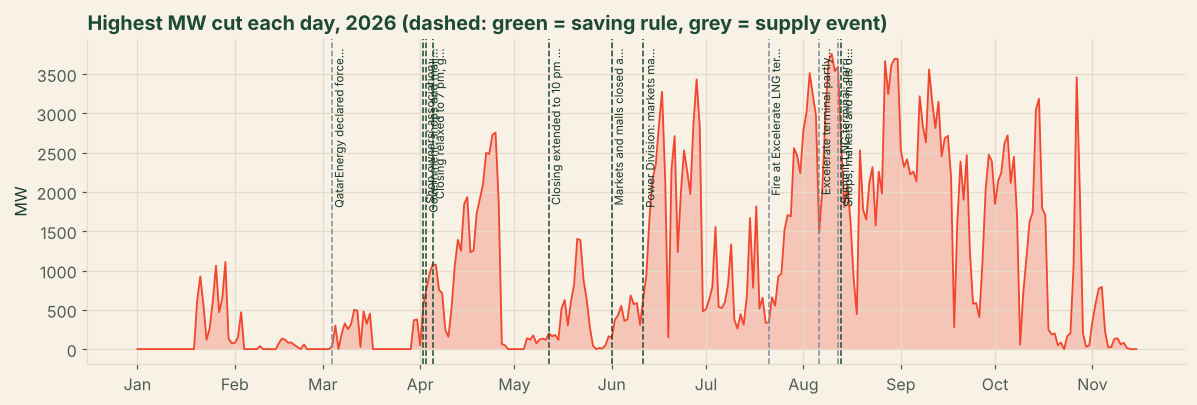

In [10]:
# 2026 day by day, with the saving rules and supply events
ev = pd.read_csv(RAW.parent/'reference/policy_events_2026.csv')
d26 = x[x.datetime >= '2026-01-01'].set_index('datetime').load_shedding.resample('D').max()
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.fill_between(d26.index, d26.values, color=TOMATO, alpha=.25, lw=0); ax.plot(d26.index, d26.values, color=TOMATO, lw=1.2)
for _, e in ev.iterrows():
    if len(str(e.date)) < 7: continue     # year only: no date to place it on
    t = pd.Timestamp(e.date) if len(str(e.date)) == 10 else pd.Timestamp(str(e.date) + '-01')
    ax.axvline(t, color=GREEN if e.type == 'rule' else SLATE, lw=1, ls='--')
    ax.text(t, ax.get_ylim()[1]*.97, ' ' + e.event[:26] + '…', rotation=90, va='top', fontsize=7.5, color=INK)
ax.set_title('Highest MW cut each day, 2026 (dashed: green = saving rule, grey = supply event)')
ax.set_ylabel('MW'); ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
plt.tight_layout(); plt.show()

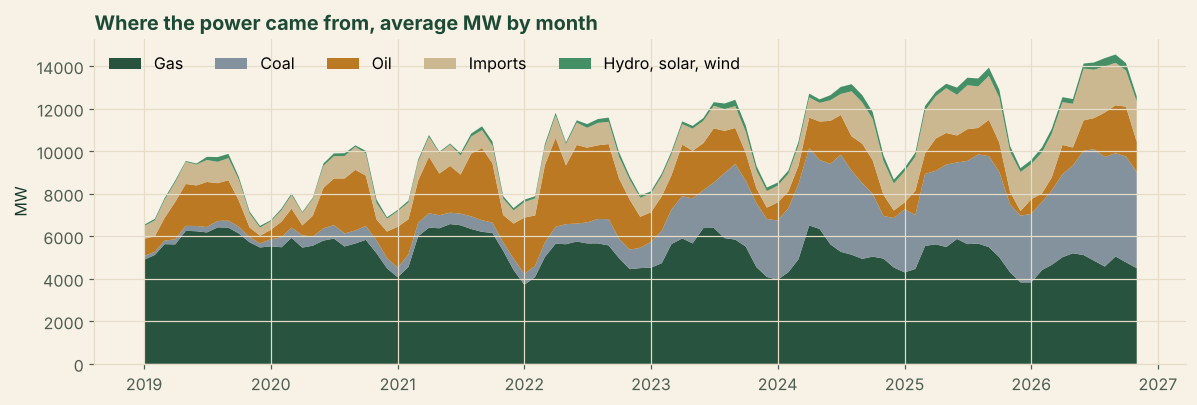

In [11]:
# Fuel mix by month (MW average)
clean = h[h.datetime >= '2019-01-01'].set_index('datetime')[parts]
clean = clean.mask(clean > 20000)          # typing errors in the source (one is about 45,000 MW of oil)
fm = clean.resample('MS').mean()
grp = pd.DataFrame({'Gas': fm.gas, 'Coal': fm.coal, 'Oil': fm.liquid_fuel,
                    'Imports': fm[['india_bheramara_hvdc','india_tripura','india_adani','nepal']].sum(axis=1),
                    'Hydro, solar, wind': fm[['hydro','solar','wind']].sum(axis=1)})
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.stackplot(grp.index, grp.T.values, labels=grp.columns, colors=[GREEN, SLATE, OCHRE, '#C9B58C', GREEN2], alpha=.95)
ax.set_title('Where the power came from, average MW by month'); ax.set_ylabel('MW')
ax.legend(frameon=False, ncol=5, loc='upper left'); plt.tight_layout(); plt.show()

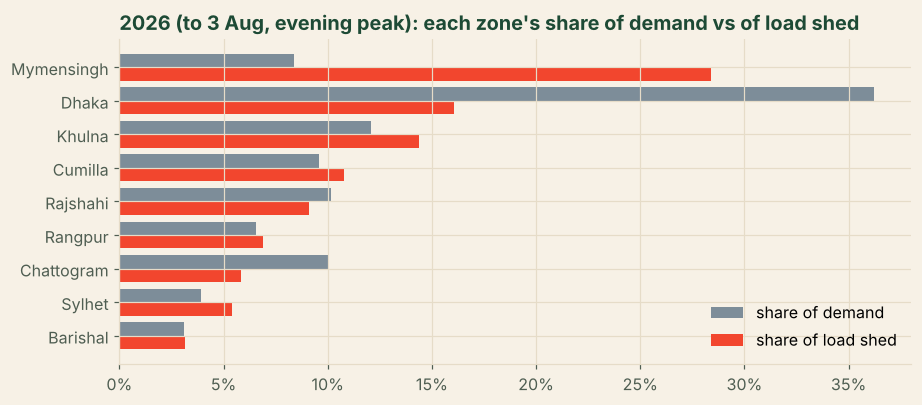

,load shed (share),demand (share)
Barishal,3.2%,3.1%
Sylhet,5.4%,3.9%
Chattogram,5.8%,10.0%
Rangpur,6.9%,6.6%
Rajshahi,9.1%,10.2%
Cumilla,10.8%,9.6%
Khulna,14.4%,12.1%
Dhaka,16.1%,36.2%
Mymensingh,28.4%,8.4%


In [12]:
# Who carries the cuts: share of load shed by zone (daily dataset, evening peak)
zones = ['Dhaka','Chattogram','Rajshahi','Mymensingh','Sylhet','Barishal','Rangpur','Cumilla','Khulna']
z = dd[dd.Date >= '2026-01-01']
share = pd.DataFrame({'load shed (share)': [z[f'{n}_load'].sum() for n in zones],
                      'demand (share)': [z[f'{n}_demand'].sum() for n in zones]}, index=zones)
share = (share / share.sum()).sort_values('load shed (share)')
fig, ax = plt.subplots(figsize=(8.5, 3.8))
yy = np.arange(len(share)); ax.barh(yy + .2, share['demand (share)'], .4, color=SLATE, label='share of demand')
ax.barh(yy - .2, share['load shed (share)'], .4, color=TOMATO, label='share of load shed')
ax.set_yticks(yy, share.index); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_title('2026 (to 3 Aug, evening peak): each zone\'s share of demand vs of load shed'); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
share.map('{:.1%}'.format)

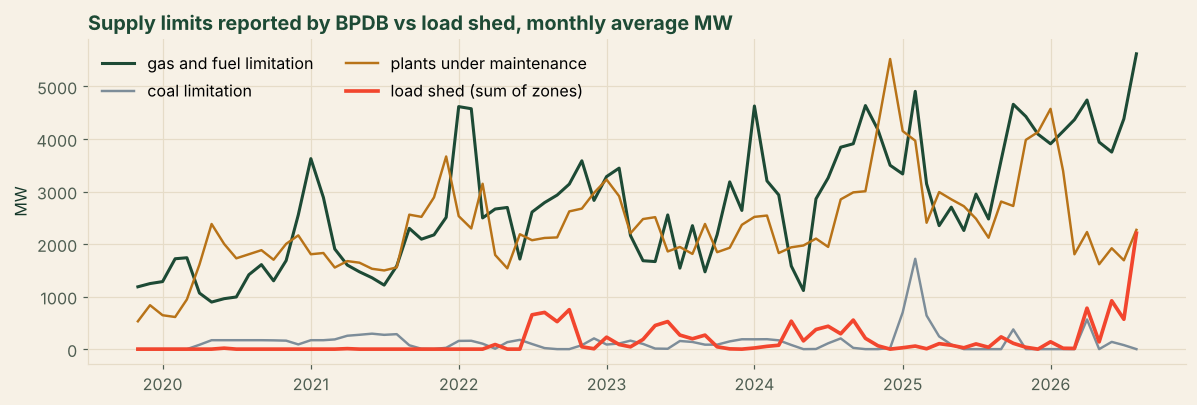

In [13]:
# Why: reported supply limits vs the day's peak load shed (daily dataset)
lim = dd.set_index('Date')[['Gas/LF limitation','Coal supply Limitation','Plants under shut down/ maintenance']]
zl = dd.set_index('Date')[[f'{n}_load' for n in zones]].sum(axis=1).rename('zone load shed total')
w = pd.concat([lim, zl], axis=1).resample('MS').mean()
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(w.index, w['Gas/LF limitation'], color=GREEN, lw=2, label='gas and fuel limitation')
ax.plot(w.index, w['Coal supply Limitation'], color=SLATE, lw=1.6, label='coal limitation')
ax.plot(w.index, w['Plants under shut down/ maintenance'], color=OCHRE, lw=1.6, label='plants under maintenance')
ax.plot(w.index, w['zone load shed total'], color=TOMATO, lw=2.4, label='load shed (sum of zones)')
ax.set_title('Supply limits reported by BPDB vs load shed, monthly average MW'); ax.set_ylabel('MW')
ax.legend(frameon=False, ncol=2); plt.tight_layout(); plt.show()

## 5. Verdict and next steps

- **Usable.** One continuous hourly record from April 2015 to mid-November 2026, two sources that agree exactly
  where they overlap, and a daily record with zone-level load shedding and supply limits to August 2026.
- **New in the plan.** The daily zones let us show who carries the cuts (question 6) with real numbers,
  and the BPDB supply limits give a direct view of why (question 11).
- **Already clear.** 2026 is the worst year on record by a wide margin: about 3,900 GWh cut by mid-November
  against 2,600 GWh in all of 2023. Mymensingh carried 28% of the zone load shed with 8% of the demand, and
  Dhaka 16% with 36% of the demand. In July to September 2026 the deepest cuts came between midnight and 3 am.
- **Silver layer fixes.** True demand = generation + load shed; flag shedding above 6,000 MW and any single fuel
  above 20,000 MW; flag fuel totals that do not add up; the missing midnight hour before March 2026; fix the 12 May 2026 duplicate; check the daily weekday labels the source warns about.
- **Next (Phase 2).** DuckDB pipeline from bronze to silver to gold, then first numbers for the 12 questions.